# Aula guiada: pré-processamento de features com dados reais

**Módulo:** Fundamentos de Machine Learning · **Duração:** 60 minutos · **Pré-requisitos:** aulas de regressão linear e regressão logística

Nesta aula, preparamos ao vivo uma base real para a regressão logística e **justificamos cada decisão** tomada no caminho. Para cada passo, o notebook mostra como o dado está **antes** e como fica **depois** do tratamento.

| Base | Linhas | Tarefa | Modelo | O que ela ensina |
|---|---|---|---|---|
| **Titanic** (passageiros do RMS Titanic, 1912) | 891 | prever se o passageiro sobreviveu | Regressão logística | tipos de variáveis, vazamento de dados, dados faltantes, one-hot, transformação log, escala |

### Roteiro

| Bloco | Conteúdo | Tempo |
|---|---|---|
| 0 | Preparação e **tipos de variáveis** (taxonomia) | 6 min |
| Etapas 1 – 2 | Primeiro contato, vazamento e colunas redundantes | 10 min |
| Etapas 3 – 4 | Diagnóstico e tratamento de dados faltantes | 16 min |
| Etapas 5 – 7 | Numéricas, categóricas e pipeline completo | 18 min |
| Fechamento | Resumo das decisões e discussão | 10 min |

### Como conduzir esta aula

- O notebook já está **executado**: dá para apresentar só mostrando as saídas ou reexecutar as células ao vivo, em ordem (leva poucos segundos).
- Os blocos **Pergunte à turma** marcam pausas: peça que a turma preveja o resultado **antes** de executar ou rolar até a célula seguinte.
- Os blocos **Decisão** resumem o que foi escolhido, por quê e qual alternativa foi descartada. São o ponto central da fala em cada etapa.
- Se o tempo apertar, a etapa **5** pode ser passada mais rápido: o essencial está nas figuras.

### Legenda das tabelas "antes e depois"

| Cor | Significado |
|---|---|
| vermelho | valor faltante (`NaN`) |
| laranja | valor que estava faltando e foi **preenchido** |
| lilás | coluna que existia e teve os valores **transformados** |
| verde | coluna **nova**, criada pelo pré-processamento |

## 0. Preparação (≈ 3 min)

A base vem do repositório público de dados de exemplo do `seaborn`. É o mesmo arquivo carregado por `seaborn.load_dataset("titanic")`. Aqui ele é lido diretamente com o `pandas`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

URL_DADOS = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/"
pd.set_option("display.max_columns", 30)

A célula abaixo define as funções que desenham as figuras de **antes e depois**. Basta executá-la; não é preciso alterar nada.

In [2]:
# ---------- Funções auxiliares de visualização (apenas execute) ----------
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "font.size": 10})
VERDE, LARANJA, ROXO, VERMELHO, CINZA = "#0f8b8d", "#d9822b", "#6c5ce7", "#c0392b", "#8a94a3"
FUNDO = {"faltante": "#f9d3cf", "imputado": "#fde2c2", "transformado": "#e6e2fb",
         "novo": "#d3eee4", "cabecalho": "#e8edf3"}


def _fmt(v, decimais):
    if pd.api.types.is_scalar(v) and pd.isna(v):
        return "NaN"
    if isinstance(v, (bool, np.bool_)):
        return str(v)
    if isinstance(v, (float, np.floating)):
        return f"{v:.0f}" if float(v).is_integer() else f"{v:.{decimais}f}"
    return str(v)


def tabela_antes_depois(antes, depois, titulo_antes="Antes", titulo_depois="Depois",
                        decimais=2, titulo=None):
    # Desenha duas tabelas lado a lado e colore o que mudou (veja a legenda no topo).
    def larguras(df):  # largura de cada coluna, em caracteres (a primeira é o índice)
        return ([max(len(str(i)) for i in df.index) + 2]
                + [max([len(str(c))] + [len(_fmt(v, decimais)) for v in df[c]]) + 3 for c in df.columns])

    POL, ALT, GAP, MARG = 0.075, 0.28, 0.9, 0.1   # polegadas por caractere, por linha, entre tabelas, margem
    la, ld = larguras(antes), larguras(depois)
    n = max(len(antes), len(depois)) + 1
    W, H = POL * (sum(la) + sum(ld)) + GAP + 2 * MARG, ALT * n + 0.5
    fig = plt.figure(figsize=(W, H))
    ax1 = fig.add_axes([MARG / W, 0.05 / H, POL * sum(la) / W, ALT * n / H])
    ax2 = fig.add_axes([(MARG + POL * sum(la) + GAP) / W, 0.05 / H, POL * sum(ld) / W, ALT * n / H])
    eixos = [ax1, ax2]
    for ax, df, tit, eh_depois, larg in [(ax1, antes, titulo_antes, False, la),
                                         (ax2, depois, titulo_depois, True, ld)]:
        ax.axis("off")
        texto = [[_fmt(v, decimais) for v in linha] for linha in df.itertuples(index=False)]
        tab = ax.table(cellText=texto, colLabels=[str(c) for c in df.columns],
                       rowLabels=[str(i) for i in df.index], cellLoc="center", bbox=[0, 0, 1, 1])
        tab.auto_set_font_size(False)
        tab.set_fontsize(9)
        for (r, c), cel in tab.get_celld().items():
            cel.set_width(larg[c + 1])
        for j, col in enumerate(df.columns):
            estados = set()
            for i, idx in enumerate(df.index):
                v = df.iloc[i, j]
                cor = "white"
                if pd.isna(v):
                    cor = FUNDO["faltante"]
                elif eh_depois and col not in antes.columns:
                    cor = FUNDO["novo"]
                    estados.add("novo")
                elif eh_depois and idx in antes.index:
                    v0 = antes.at[idx, col]
                    if pd.isna(v0):
                        cor = FUNDO["imputado"]
                        estados.add("imputado")
                    elif _fmt(v0, decimais) != _fmt(v, decimais):
                        cor = FUNDO["transformado"]
                        estados.add("transformado")
                tab[i + 1, j].set_facecolor(cor)
            cab = tab[0, j]
            cab.set_text_props(weight="bold")
            if "novo" in estados:
                cab.set_facecolor(FUNDO["novo"])
            elif "transformado" in estados:
                cab.set_facecolor(FUNDO["transformado"])
            elif "imputado" in estados:
                cab.set_facecolor(FUNDO["imputado"])
            else:
                cab.set_facecolor(FUNDO["cabecalho"])
        for i in range(len(df)):
            tab[i + 1, -1].set_text_props(color=CINZA)
            tab[i + 1, -1].set_edgecolor("#d8dee6")
        ax.set_title(tit, pad=5)
    fig.text((MARG + POL * sum(la) + GAP * 0.4) / W, (0.05 + ALT * n / 2) / H, "→",
             fontsize=24, ha="center", va="center", color=CINZA)
    if titulo:
        fig.suptitle(titulo, fontweight="bold", y=1.02)
    plt.show()


def hist_antes_depois(antes, depois, titulo_antes, titulo_depois, bins=40,
                      cor_antes=LARANJA, cor_depois=VERDE, rotulo_y="quantidade"):
    # Histogramas lado a lado com o coeficiente de assimetria de cada distribuição.
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
    for ax, s, tit, cor in [(a1, antes, titulo_antes, cor_antes), (a2, depois, titulo_depois, cor_depois)]:
        s = pd.Series(np.asarray(s).ravel()).dropna()
        ax.hist(s, bins=bins, color=cor, edgecolor="white", linewidth=0.4)
        ax.set_title(tit)
        ax.set_ylabel(rotulo_y)
        ax.text(0.97, 0.92, f"assimetria = {s.skew():.2f}", transform=ax.transAxes,
                ha="right", fontsize=9, bbox=dict(facecolor="white", edgecolor="#d8dee6"))
    plt.tight_layout()
    plt.show()


print("Funções auxiliares carregadas.")

Funções auxiliares carregadas.


---
## 0.1 Antes de começar: que tipos uma variável pode assumir? (≈ 3 min)

Todo pré-processamento começa com uma pergunta: **que tipo de informação esta coluna carrega?** A resposta define o tratamento. Um modelo linear só faz contas com números, então cada tipo precisa ser convertido de um jeito diferente.

![Taxonomia dos tipos de variáveis](https://github.com/joelsonSantos/aulas-machine-learning/blob/main/assets/taxonomia_variaveis.png?raw=true)

**Como ler a árvore:**
- **Numéricas** representam **quantidades**. Faz sentido somar, subtrair e calcular a média.
  - *Contínuas* podem assumir qualquer valor num intervalo (idade, preço, peso).
  - *Discretas* são contagens inteiras (número de irmãos a bordo).
- **Categóricas** representam **grupos ou rótulos**. A média não faz sentido: qual seria a "média" entre Southampton e Cherbourg?
  - *Nominais* não têm ordem (porto de embarque).
  - *Ordinais* têm uma ordem natural (classe da passagem, escolaridade).
  - *Binárias* têm só dois valores. São um caso particular, mas aparecem tanto que merecem destaque.

**O ponto mais importante:** o tipo **semântico**, o que o valor significa, nem sempre coincide com o tipo que o `pandas` mostra em `dtype`. `pclass` é armazenada como inteiro, mas tratá-la como quantidade seria dizer que a 3ª classe vale "três vezes" a 1ª.

> **Pergunte à turma:** pensem numa tabela de clientes de um banco. Deem um exemplo de cada um dos cinco tipos. (Sugestões: renda → contínua; número de cartões → discreta; estado → nominal; faixa de risco baixo/médio/alto → ordinal; possui empréstimo sim/não → binária.)

---
# Titanic: quem sobreviveu? (regressão logística)

## Etapa 1 — Primeiro contato (≈ 5 min)

Antes de transformar qualquer coisa, olhe os dados. Três perguntas guiam o diagnóstico:
1. **Que tipo de informação** cada coluna carrega? Considere o significado, não só o `dtype`.
2. **Quanto falta** em cada coluna?
3. Alguma coluna **não deveria** estar aqui?

In [3]:
titanic = pd.read_csv(URL_DADOS + "titanic.csv")
print("Formato:", titanic.shape)
titanic.head(8)

Formato: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False


In [4]:
resumo = pd.DataFrame({
    "dtype": titanic.dtypes.astype(str),
    "valores_distintos": titanic.nunique(),
    "faltantes": titanic.isna().sum(),
    "%_faltantes": (titanic.isna().mean() * 100).round(1),
    "exemplo": titanic.iloc[1],
})
resumo

,dtype,valores_distintos,faltantes,%_faltantes,exemplo
survived,int64,2,0,0.0,1
pclass,int64,3,0,0.0,1
sex,str,2,0,0.0,female
age,float64,88,177,19.9,38.0
sibsp,int64,7,0,0.0,1
parch,int64,7,0,0.0,0
fare,float64,248,0,0.0,71.2833
embarked,str,3,2,0.2,C
class,str,3,0,0.0,First
who,str,3,0,0.0,woman


> **Pergunte à turma:** usando a árvore da seção 0.1, qual é o tipo de cada coluna do Titanic? Deixe a turma responder antes de mostrar a tabela abaixo.

### Tipo semântico de cada coluna

| coluna | `dtype` | tipo semântico | comentário |
|---|---|---|---|
| `survived` | int64 | binária (**alvo**) | 0 = não sobreviveu, 1 = sobreviveu |
| `pclass` | int64 | **categórica ordinal** | 1ª < 2ª < 3ª classe. O `dtype` é numérico, mas o significado é uma categoria com ordem |
| `sex` | texto | **binária** | dois valores |
| `age` | float64 | numérica contínua | tem valores fracionários para bebês (0,42 = 5 meses) |
| `sibsp`, `parch` | int64 | numérica discreta | contagens de irmãos/cônjuges e pais/filhos a bordo |
| `fare` | float64 | numérica contínua | tarifa em libras, muito assimétrica (máx. 512) |
| `embarked` | texto | **categórica nominal** | porto: S (Southampton), C (Cherbourg), Q (Queenstown) |
| `deck` | texto | categórica | conveses A a G. Há uma ordem física (A no topo), mas aqui ela será tratada como nominal |

A tabela também mostra colunas que **repetem** informação: `class` × `pclass`, `embark_town` × `embarked`. A coluna `alive` merece uma investigação à parte (próximo bloco).

## Etapa 2 — Vazamento de dados e colunas redundantes (≈ 5 min)

A versão da base que usamos traz colunas **derivadas** de outras.

> **Pergunte à turma:** olhando a lista de colunas de `titanic.head()`, alguma delas parece "boa demais" para prever quem sobreviveu?

Compare `alive` com o alvo:

In [5]:
pd.crosstab(titanic["alive"], titanic["survived"])

survived,0,1
alive,,
no,549,0
yes,0,342


`alive == "yes"` acontece **exatamente** quando `survived == 1`. Essa coluna é o próprio alvo escrito de outra forma. Se ela entrar no modelo:
- a acurácia no treino e no teste chega perto de 100%;
- em produção a coluna não existe, porque ninguém sabe se o passageiro sobreviveu antes de o modelo prever.

Isso é **vazamento de dados** (*data leakage*): uma feature carrega informação que **não estaria disponível no momento da previsão**.

> **Decisão: colunas removidas**
>
> | coluna | motivo |
> |---|---|
> | `alive` | **vazamento**: é o alvo |
> | `class` | duplica `pclass` (First/Second/Third = 1/2/3) |
> | `embark_town` | duplica `embarked` (Southampton = S, ...) |
> | `who`, `adult_male` | derivadas de `sex` + `age`; removidas para manter o foco da aula |
> | `alone` | derivada de `sibsp + parch == 0` |
>
> **Por quê:** colunas duplicadas não acrescentam informação e, em modelos lineares, criam colinearidade, o que torna os coeficientes instáveis e difíceis de interpretar.
>
> **Alternativa descartada:** manter `who`. Ela é legítima (não vaza o alvo) e poderia ser testada depois como **engenharia de features**.

In [6]:
colunas_removidas = ["class", "embark_town", "who", "adult_male", "alone", "alive"]

dados = titanic.drop(columns=colunas_removidas)
X = dados.drop(columns="survived")
y = dados["survived"]
print("Features que seguem para o modelo:", X.columns.tolist())

Features que seguem para o modelo: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'deck']


### Separar treino e teste **antes** de qualquer tratamento

Daqui em diante, toda estatística usada para transformar os dados (mediana, moda, média, desvio padrão, lista de categorias) será **aprendida apenas no treino**. O conjunto de teste faz o papel de "passageiros que ainda não vimos". Se ele ajudar a calcular a mediana, por exemplo, a avaliação deixa de ser honesta.

`stratify=y` mantém a mesma proporção de sobreviventes (≈ 38%) nos dois conjuntos.

In [7]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Treino: {X_treino.shape}  |  Teste: {X_teste.shape}")
print(f"Taxa de sobrevivência  treino: {y_treino.mean():.1%}  |  teste: {y_teste.mean():.1%}")

Treino: (712, 8)  |  Teste: (179, 8)
Taxa de sobrevivência  treino: 38.3%  |  teste: 38.5%


## Etapa 3 — Diagnóstico de dados faltantes (≈ 8 min)

Antes de escolher uma técnica de preenchimento, responda a duas perguntas: **quanto** falta e **se o fato de faltar diz algo** sobre o alvo.

> **Pergunte à turma:** um passageiro sem idade registrada tem mais ou menos chance de ter sobrevivido? E um sem cabine registrada?

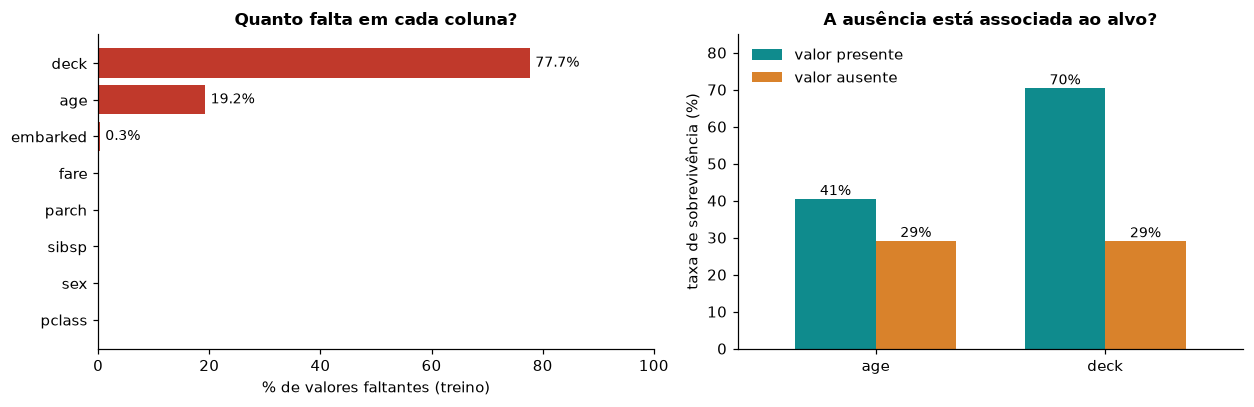

In [8]:
pct_faltantes = (X_treino.isna().mean() * 100).sort_values()
taxa_sobrevivencia = pd.DataFrame({
    col: y_treino.groupby(X_treino[col].isna()).mean() * 100 for col in ["age", "deck"]
}).rename(index={False: "valor presente", True: "valor ausente"})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
cores = [VERMELHO if v > 0 else CINZA for v in pct_faltantes.values]
ax1.barh(pct_faltantes.index, pct_faltantes.values, color=cores)
for i, v in enumerate(pct_faltantes.values):
    if v > 0:
        ax1.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)
ax1.set_xlim(0, 100)
ax1.set_xlabel("% de valores faltantes (treino)")
ax1.set_title("Quanto falta em cada coluna?")

taxa_sobrevivencia.T.plot.bar(ax=ax2, color=[VERDE, LARANJA], rot=0, width=0.7)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 1),
                 ha="center", fontsize=9)
ax2.set_ylabel("taxa de sobrevivência (%)")
ax2.set_ylim(0, 85)
ax2.set_title("A ausência está associada ao alvo?")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()

**Leitura dos gráficos:**
- `deck` está ausente em **~77%** dos passageiros, e `age` em **~20%**. `embarked` tem apenas 2 ausências.
- Entre os passageiros **sem** `deck` registrado, a taxa de sobrevivência é **menos da metade** da dos que têm o convés registrado. Para `age`, a diferença é menor, mas também existe.

Ou seja, **a ausência não é aleatória e carrega informação sobre o alvo**. A tabela abaixo ajuda a entender o porquê: o registro da cabine dependia da classe do passageiro.

In [9]:
# Para cada classe (linha), que % dos passageiros tem o convés registrado?
# X_treino["deck"].isna() vale True quando o deck está ausente e False quando está presente.
# normalize="index" transforma as contagens em proporções que somam 1 em cada linha.
tabela = pd.crosstab(X_treino["pclass"], X_treino["deck"].isna(), normalize="index")
tabela.columns = ["deck presente", "deck ausente"]   # False -> presente, True -> ausente
(tabela * 100).round(1)                              # em %

,deck presente,deck ausente
pclass,,
1,78.9,21.1
2,10.0,90.0
3,2.3,97.7


**Como ler:** cada linha soma 100%. Na 1ª classe, cerca de **79%** dos passageiros têm o convés registrado. Na 3ª classe, menos de **3%**.

O convés é conhecido para a maioria dos passageiros de 1ª classe e quase nunca para os de 3ª. A ausência de `deck` funciona, na prática, como um **sinal indireto da classe**, que por sua vez está associada à sobrevivência.

### E se simplesmente removermos as linhas incompletas?

In [10]:
print(f"Linhas no treino:                              {len(X_treino)}")
print(f"Após dropna() considerando todas as colunas:   {len(X_treino.dropna())}")
print(f"Após remover apenas as linhas sem idade:       {X_treino['age'].notna().sum()}")
print(f"Passageiros do TESTE sem idade:                {X_teste['age'].isna().sum()} de {len(X_teste)}")

Linhas no treino:                              712
Após dropna() considerando todas as colunas:   141
Após remover apenas as linhas sem idade:       575
Passageiros do TESTE sem idade:                40 de 179


- `dropna()` em todas as colunas deixaria **cerca de 1 em cada 5 linhas**, e quase só passageiros de 1ª classe, porque são eles que têm `deck`. O modelo aprenderia sobre uma população diferente da real.
- Mesmo removendo só as linhas sem idade, o problema volta **na hora de prever**: dezenas de passageiros do teste não têm idade e o modelo precisa dar uma resposta para eles.

> **Decisão: estratégia para cada coluna com faltantes**
>
> | coluna | % faltante | o que sabemos | estratégia | por quê |
> |---|---|---|---|---|
> | `embarked` | ~0,3% | 2 casos isolados | **moda** (porto mais frequente) | o impacto é desprezível; não justifica nada mais complexo |
> | `age` | ~20% | ausência associada a menor sobrevivência | **mediana + indicador de ausência** | a mediana é robusta a idades extremas; o indicador preserva o sinal "idade não registrada" |
> | `deck` | ~77% | ausência fortemente associada à classe e ao alvo | **categoria `"desconhecido"`** | remover a coluna perderia o sinal; preencher com a moda inventaria cabines para 3/4 dos passageiros |
>
> **Alternativa descartada:** imputação por KNN ou iterativa para `age`. É possível, mas acrescenta complexidade, e a mediana + indicador é a linha de base recomendada. Uma questão aberta no fechamento convida a comparar.

## Etapa 4 — Imputação: antes e depois (≈ 8 min)

O `SimpleImputer` funciona em duas etapas, como todo transformador do scikit-learn:
- `fit(X_treino)`: **aprende** a estatística (mediana, moda...) usando somente o treino;
- `transform(X)`: **aplica** essa estatística ao treino e, depois, ao teste.

Com `add_indicator=True`, ele também cria a coluna `missingindicator_age`, que vale 1 quando a idade estava ausente.

`make_column_transformer` aplica um imputador diferente a cada grupo de colunas. `.set_output(transform="pandas")` faz o resultado sair como `DataFrame`, com nomes de colunas, o que é ótimo para inspecionar.

In [11]:
imputador_idade = SimpleImputer(strategy="median", add_indicator=True)
imputador_embarque = SimpleImputer(strategy="most_frequent")
imputador_deck = SimpleImputer(strategy="constant", fill_value="desconhecido")

imputacao = make_column_transformer(
    (imputador_idade, ["age"]),
    (imputador_embarque, ["embarked"]),
    (imputador_deck, ["deck"]),
    verbose_feature_names_out=False,
).set_output(transform="pandas")

imputacao.fit(X_treino)                      # aprende SÓ com o treino
X_treino_imp = imputacao.transform(X_treino)

print("Mediana de idade aprendida no treino:", imputacao.named_transformers_["simpleimputer-1"].statistics_[0])
print("Porto mais frequente no treino:     ", imputacao.named_transformers_["simpleimputer-2"].statistics_[0])
print("Colunas geradas:", X_treino_imp.columns.tolist())

Mediana de idade aprendida no treino: 28.5
Porto mais frequente no treino:      S
Colunas geradas: ['age', 'missingindicator_age', 'embarked', 'deck']


### Como o dado ficou

A figura mostra os mesmos passageiros antes e depois. Repare nas células **laranja** (valores preenchidos) e na coluna **verde** `missingindicator_age`, que registra quais idades foram inventadas.

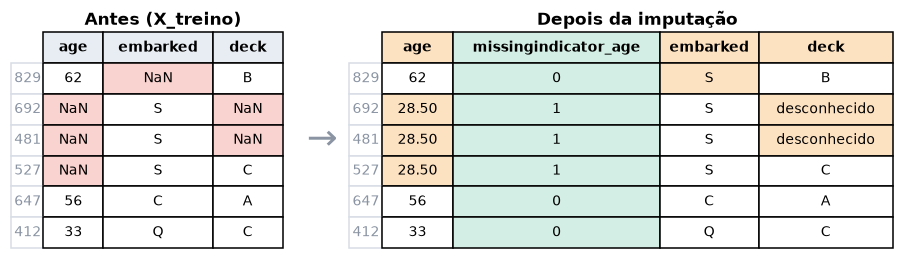

In [12]:
# alguns passageiros com cada tipo de ausência (dict.fromkeys remove repetidos)
linhas = list(dict.fromkeys(
    list(X_treino.index[X_treino["embarked"].isna()][:1])
    + list(X_treino.index[X_treino["age"].isna()][:3])
    + list(X_treino.index[X_treino["deck"].notna() & X_treino["embarked"].notna()][:3])))

tabela_antes_depois(X_treino.loc[linhas, ["age", "embarked", "deck"]],
                    X_treino_imp.loc[linhas],
                    "Antes (X_treino)", "Depois da imputação")

### O efeito colateral da imputação pela mediana

> **Pergunte à turma:** o que acontece com o histograma de idade se preenchermos ~140 idades com o mesmo número?

Preencher todas com a mediana cria um **pico artificial** no histograma.

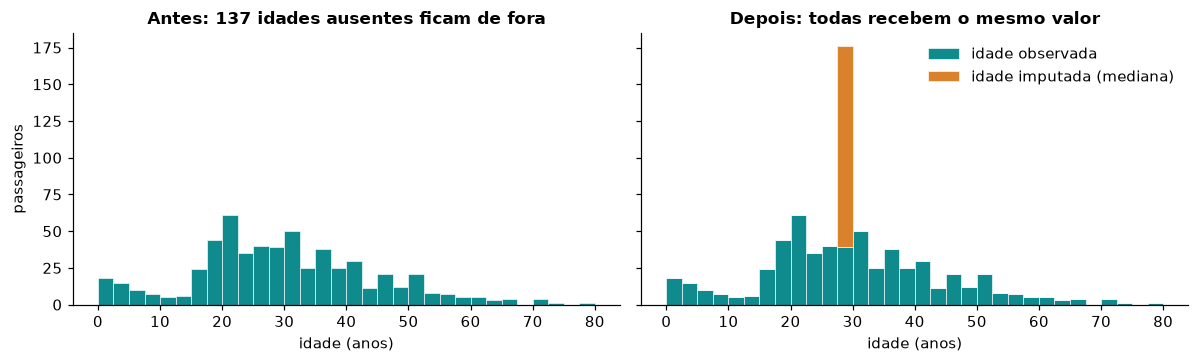

Desvio padrão da idade  antes: 14.49  |  depois: 13.03


In [13]:
faltava = X_treino["age"].isna()
bins = np.arange(0, 82.5, 2.5)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
a1.hist(X_treino["age"].dropna(), bins=bins, color=VERDE, edgecolor="white", linewidth=0.4)
a1.set_title(f"Antes: {faltava.sum()} idades ausentes ficam de fora")
a2.hist([X_treino_imp.loc[~faltava, "age"], X_treino_imp.loc[faltava, "age"]], bins=bins,
        stacked=True, color=[VERDE, LARANJA], edgecolor="white", linewidth=0.4,
        label=["idade observada", "idade imputada (mediana)"])
a2.set_title("Depois: todas recebem o mesmo valor")
a2.legend(frameon=False)
for ax in (a1, a2):
    ax.set_xlabel("idade (anos)")
a1.set_ylabel("passageiros")
plt.tight_layout()
plt.show()

print(f"Desvio padrão da idade  antes: {X_treino['age'].std():.2f}  |  depois: {X_treino_imp['age'].std():.2f}")

**Por que isso importa:** a imputação reduz a variabilidade (o desvio padrão cai) e mistura dois grupos diferentes no mesmo valor: quem tem de fato ~28 anos e quem não teve a idade registrada. É por isso que mantemos `missingindicator_age`. Com ele, o modelo linear aprende um **coeficiente próprio** para "idade não registrada" e não depende só do valor inventado.

> **Decisão:** mediana, e não média.
>
> **Por quê:** a idade tem uma cauda de passageiros idosos e de bebês. A mediana não é puxada por esses extremos. Aqui a diferença é pequena (no treino, média ≈ 29,8 e mediana = 28,5), mas em variáveis muito assimétricas, como `fare`, ela seria grande.

## Etapa 5 — Numéricas: assimetria e escala (≈ 7 min)

### `fare`: uma distribuição de cauda longa

A maioria pagou menos de 30 libras, mas alguns pagaram mais de 500. Em um modelo linear, esses poucos valores extremos têm peso desproporcional. Aplicamos `log(1 + fare)`:
- o **log** transforma diferenças multiplicativas em aditivas: ir de 10 para 20 libras passa a pesar o mesmo que ir de 100 para 200;
- o **+1** (`np.log1p`) é necessário porque há tarifas **iguais a zero**, e `log(0)` não existe.

`FunctionTransformer` embrulha qualquer função para que ela funcione como um transformador do scikit-learn e possa entrar em um `Pipeline`.

Tarifas iguais a zero no treino: 14


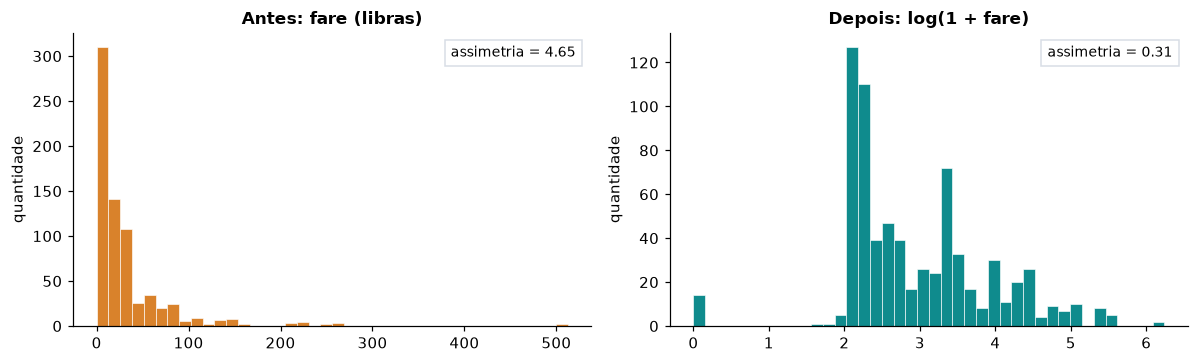

In [14]:
log_tarifa = FunctionTransformer(np.log1p, feature_names_out="one-to-one").set_output(transform="pandas")
tarifa_log = log_tarifa.fit_transform(X_treino[["fare"]])

print("Tarifas iguais a zero no treino:", (X_treino["fare"] == 0).sum())
hist_antes_depois(X_treino["fare"], tarifa_log["fare"],
                  "Antes: fare (libras)", "Depois: log(1 + fare)")

O coeficiente de **assimetria** cai para perto de zero, e a distribuição fica muito mais simétrica.

> **Decisão:** `log1p` em `fare`.
>
> **Alternativa considerada:** `RobustScaler` (usa mediana e intervalo interquartil). Ele reduz a influência dos extremos na **escala**, mas não muda o **formato** da distribuição. Como a tarifa tem uma relação mais "multiplicativa" com o padrão de vida do passageiro, o log faz mais sentido.

### Colocando tudo na mesma escala

A `LogisticRegression` do scikit-learn usa **regularização L2 por padrão** (`C=1.0`). A penalização atua sobre o tamanho dos coeficientes. Se uma feature varia de 0 a 80 (idade) e outra de 0 a 8 (`sibsp`), a penalização trata as duas de forma desigual. O `StandardScaler` deixa todas com média 0 e desvio padrão 1.

> **Decisão:** `pclass` entra como **numérica ordinal** (1, 2, 3) e é padronizada.
>
> **Por quê:** a ordem 1ª < 2ª < 3ª é real e são apenas 3 níveis. Um único coeficiente captura a tendência "quanto pior a classe, menor a chance".
>
> **Alternativa:** one-hot, com um coeficiente por classe, sem supor degraus iguais. É uma das questões abertas do fechamento.

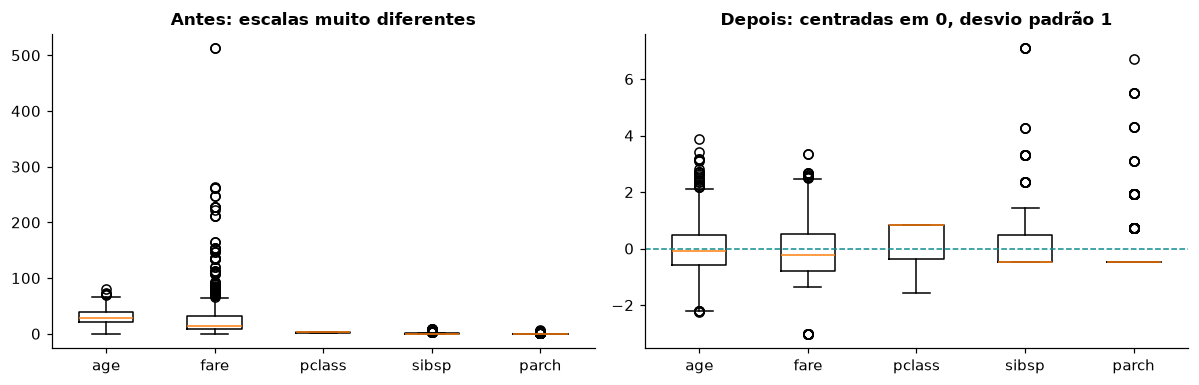

In [15]:
numericas = ["age", "fare", "pclass", "sibsp", "parch"]

escala = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["age"]),
    (make_pipeline(log_tarifa, StandardScaler()), ["fare"]),
    (StandardScaler(), ["pclass", "sibsp", "parch"]),
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_num = escala.fit_transform(X_treino)[numericas]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.boxplot([X_treino[c].dropna() for c in numericas])
a1.set_xticks(range(1, len(numericas) + 1), numericas)
a1.set_title("Antes: escalas muito diferentes")
a2.boxplot([X_num[c] for c in numericas])
a2.set_xticks(range(1, len(numericas) + 1), numericas)
a2.axhline(0, color=VERDE, linestyle="--", linewidth=1)
a2.set_title("Depois: centradas em 0, desvio padrão 1")
plt.tight_layout()
plt.show()

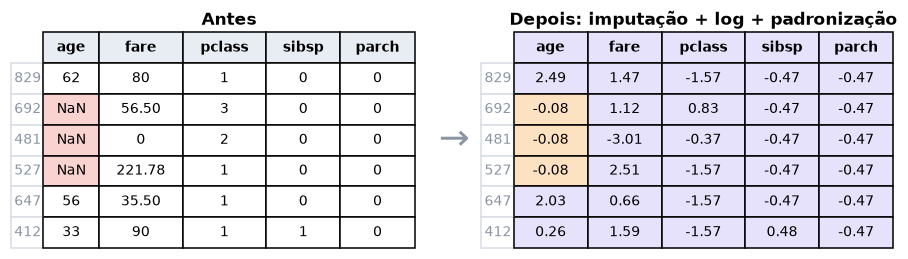

In [16]:
tabela_antes_depois(X_treino.loc[linhas, numericas], X_num.loc[linhas],
                    "Antes", "Depois: imputação + log + padronização")

Na tabela, `fare` foi transformada (log + escala), e as idades ausentes foram preenchidas **e** padronizadas. Um valor como `-0.08` em `age` significa "um pouco abaixo da idade mediana do treino".

## Etapa 6 — Categóricas: one-hot encoding (≈ 4 min)

Se codificássemos `embarked` como S = 0, C = 1, Q = 2, o modelo aprenderia **um único coeficiente** e entenderia que Queenstown tem "o dobro" do efeito de Cherbourg. Essa ordem não existe. No **one-hot**, cada porto vira uma coluna 0/1 com seu próprio coeficiente.

> **Decisão:** `OneHotEncoder(handle_unknown="ignore")` para `sex`, `embarked` e `deck`.
>
> - `handle_unknown="ignore"`: se aparecer no teste uma categoria que não existia no treino, a linha recebe zeros em vez de gerar erro.
> - **Armadilha das dummies:** as colunas de uma mesma feature sempre somam 1, o que repete o intercepto. Com a regularização padrão da `LogisticRegression`, isso não é um problema. Em uma regressão linear **sem** regularização, use `drop="first"` para ter coeficientes interpretáveis.

Colunas criadas: ['sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S', 'deck_A', 'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_desconhecido']


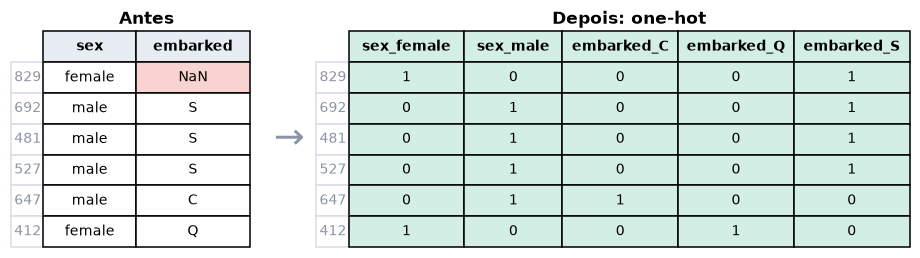

In [17]:
categoricas = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="most_frequent"),
                   OneHotEncoder(handle_unknown="ignore", sparse_output=False)), ["sex", "embarked"]),
    (make_pipeline(SimpleImputer(strategy="constant", fill_value="desconhecido"),
                   OneHotEncoder(handle_unknown="ignore", sparse_output=False)), ["deck"]),
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_cat = categoricas.fit_transform(X_treino)
print("Colunas criadas:", X_cat.columns.tolist())

colunas_sex_emb = [c for c in X_cat.columns if c.startswith(("sex_", "embarked_"))]
tabela_antes_depois(X_treino.loc[linhas, ["sex", "embarked"]], X_cat.loc[linhas, colunas_sex_emb],
                    "Antes", "Depois: one-hot")

De 2 colunas de texto nasceram 5 colunas numéricas. `deck` sozinha gera 8 colunas (A a G, mais `desconhecido`). A linha que tinha `embarked` ausente (laranja na tabela da etapa 4) aparece aqui já com o porto mais frequente.

## Etapa 7 — Pipeline completo e comparação das decisões (≈ 7 min)

Agora juntamos tudo em **um único objeto**. O `Pipeline` garante que, em cada rodada da validação cruzada, os imputadores, o log, o scaler e o one-hot sejam reajustados **somente com as dobras de treino**. É isso que impede o vazamento.

Para medir o efeito das decisões sobre faltantes, a função abaixo monta o pré-processamento **com e sem** o indicador de idade e **com e sem** a coluna `deck`.

> **Pergunte à turma:** qual das quatro variantes vai ter a maior acurácia? A diferença será grande?

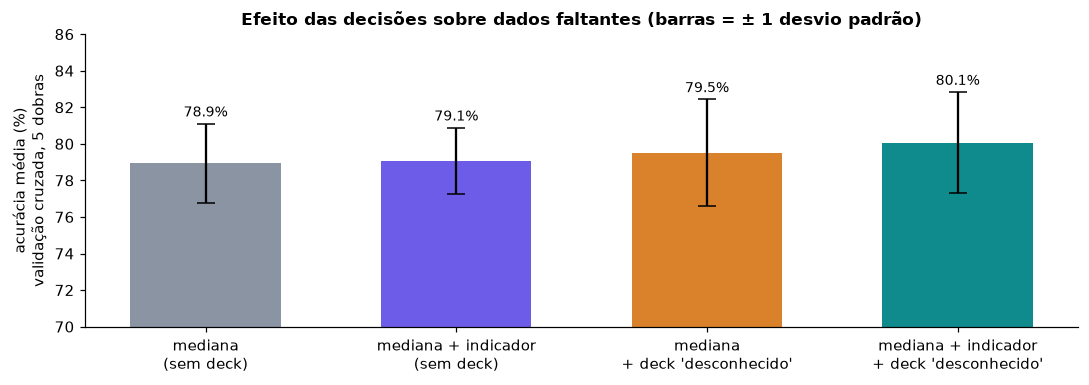

In [18]:
def montar_preprocessamento(indicador_idade=True, usar_deck=True):
    etapas = [
        (make_pipeline(SimpleImputer(strategy="median", add_indicator=indicador_idade),
                       StandardScaler()), ["age"]),
        (make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                       StandardScaler()), ["fare"]),
        (StandardScaler(), ["pclass", "sibsp", "parch"]),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore", sparse_output=False)), ["sex", "embarked"]),
    ]
    if usar_deck:
        etapas.append((make_pipeline(SimpleImputer(strategy="constant", fill_value="desconhecido"),
                                     OneHotEncoder(handle_unknown="ignore", sparse_output=False)), ["deck"]))
    return make_column_transformer(*etapas, verbose_feature_names_out=False)


variantes = {
    "mediana\n(sem deck)": montar_preprocessamento(False, False),
    "mediana + indicador\n(sem deck)": montar_preprocessamento(True, False),
    "mediana\n+ deck 'desconhecido'": montar_preprocessamento(False, True),
    "mediana + indicador\n+ deck 'desconhecido'": montar_preprocessamento(True, True),
}

resultados = {}
for nome, prep in variantes.items():
    modelo = make_pipeline(prep, LogisticRegression(max_iter=1000))
    resultados[nome] = cross_val_score(modelo, X_treino, y_treino, cv=5, scoring="accuracy")

medias = pd.Series({k: v.mean() for k, v in resultados.items()})
desvios = pd.Series({k: v.std() for k, v in resultados.items()})

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(medias.index, medias.values * 100, yerr=desvios.values * 100, capsize=6,
       color=[CINZA, ROXO, LARANJA, VERDE], width=0.6)
for i, v in enumerate(medias.values):
    ax.text(i, v * 100 + desvios.values[i] * 100 + 0.4, f"{v:.1%}", ha="center", fontsize=9)
ax.set_ylim(70, 86)
ax.set_ylabel("acurácia média (%)\nvalidação cruzada, 5 dobras")
ax.set_title("Efeito das decisões sobre dados faltantes (barras = ± 1 desvio padrão)")
plt.tight_layout()
plt.show()

**Como interpretar com honestidade:** as diferenças entre as variantes são de cerca de **1 ponto percentual**, **menores que a variação entre as dobras** (as barras de erro). Com apenas 712 passageiros no treino, não é possível afirmar que uma variante seja claramente superior.

O ganho principal das decisões da etapa 3 não é um salto de acurácia. Elas permitem:
- **usar todas as linhas** no treino, em vez de 1/5 delas com `dropna()`;
- **prever para qualquer passageiro novo**, mesmo sem idade ou cabine;
- deixar o modelo **aprender explicitamente** o efeito de "dado ausente", como mostram os coeficientes abaixo.

Agora treinamos a variante completa com todo o treino e a avaliamos **uma única vez** no teste.

Acurácia no teste: 79.9%
Referência ingênua (prever sempre 'não sobreviveu'): 61.5%


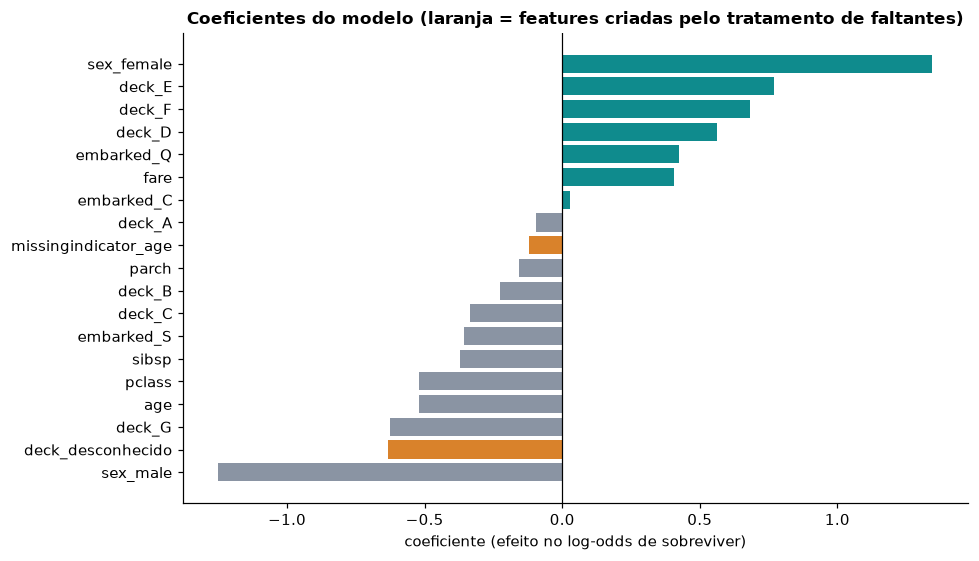

In [19]:
modelo_titanic = make_pipeline(montar_preprocessamento(True, True), LogisticRegression(max_iter=1000))
modelo_titanic.fit(X_treino, y_treino)
print(f"Acurácia no teste: {accuracy_score(y_teste, modelo_titanic.predict(X_teste)):.1%}")
print(f"Referência ingênua (prever sempre 'não sobreviveu'): {1 - y_teste.mean():.1%}")

nomes = modelo_titanic[0].get_feature_names_out()
coef = pd.Series(modelo_titanic[-1].coef_[0], index=nomes).sort_values()
destaque = {"missingindicator_age", "deck_desconhecido"}

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(coef.index, coef.values,
        color=[LARANJA if n in destaque else (VERDE if v > 0 else CINZA) for n, v in coef.items()])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("coeficiente (efeito no log-odds de sobreviver)")
ax.set_title("Coeficientes do modelo (laranja = features criadas pelo tratamento de faltantes)")
plt.tight_layout()
plt.show()

**Leitura dos coeficientes:**
- `sex_male` tem o maior coeficiente negativo, refletindo a política "mulheres e crianças primeiro";
- `pclass` é negativo: quanto pior a classe, menor a chance;
- `deck_desconhecido` e `missingindicator_age` são **negativos**, e `deck_desconhecido` está entre os menores coeficientes de `deck` (`deck_G` também é baixo, mas só 4 passageiros estão nesse convés). O modelo aprendeu que "não ter cabine registrada" e "não ter idade registrada" estão associados a menor sobrevivência, exatamente o padrão visto no diagnóstico da etapa 3. Esse sinal teria sido perdido com `dropna()` ou com a remoção da coluna `deck`.

> Lembre-se: os coeficientes são comparáveis entre si **porque as features foram padronizadas**.

---
# Fechamento (≈ 10 min)

## Resumo das decisões

| coluna | problema encontrado | decisão | técnica no scikit-learn |
|---|---|---|---|
| `alive` | é o alvo escrito de outra forma | remover (vazamento) | `df.drop` |
| `class`, `embark_town`, ... | duplicadas ou derivadas | remover | `df.drop` |
| `age` | 20% ausente; ausência associada ao alvo | mediana + indicador | `SimpleImputer(strategy="median", add_indicator=True)` |
| `deck` | 77% ausente; ausência associada à classe | categoria "desconhecido" + one-hot | `SimpleImputer(strategy="constant")`, `OneHotEncoder` |
| `embarked` | 2 ausentes; nominal | moda + one-hot | `SimpleImputer(strategy="most_frequent")`, `OneHotEncoder` |
| `fare` | cauda longa, tarifas iguais a zero | log(1 + x) + padronização | `FunctionTransformer(np.log1p)`, `StandardScaler` |
| numéricas | escalas diferentes + regularização L2 | padronização | `StandardScaler` |
| todas | risco de vazamento na avaliação | tudo dentro do pipeline, ajustado só no treino | `make_pipeline`, `make_column_transformer` |

In [20]:
# Q2 — pclass numérica × one-hot
def preprocessamento_pclass_onehot():
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), ["age"]),
        (make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), ["fare"]),
        (StandardScaler(), ["sibsp", "parch"]),
        (OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["pclass"]),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore", sparse_output=False)), ["sex", "embarked"]),
        (make_pipeline(SimpleImputer(strategy="constant", fill_value="desconhecido"),
                       OneHotEncoder(handle_unknown="ignore", sparse_output=False)), ["deck"]),
    )

for nome, prep in [("pclass numérica", montar_preprocessamento(True, True)),
                   ("pclass one-hot", preprocessamento_pclass_onehot())]:
    notas = cross_val_score(make_pipeline(prep, LogisticRegression(max_iter=1000)), X_treino, y_treino, cv=5)
    print(f"{nome:16s} acurácia: {notas.mean():.1%} ± {notas.std():.1%}")

pclass numérica  acurácia: 80.1% ± 2.8%
pclass one-hot   acurácia: 80.3% ± 2.4%
